# 03 · Auditoría de `replenishment_signal`
El diccionario dice que la señal la calcula el sistema de reposición «con base en la demanda observada». Si en realidad incorpora la demanda del día que queremos pronosticar (o de días posteriores), usarla sería **fuga de información**: las métricas de validación saldrían muy buenas y en producción el modelo no tendría ese dato.

Complementa la sección 7 de `01_eda.ipynb` con cuatro pruebas:
1. **Correlación cruzada:** ¿con qué día de demanda se parece la señal?
2. **Reconstrucción exacta:** ¿es una función de otras columnas? ¿cuál ventana?
3. **Fuga indirecta:** ¿un rezago pequeño basta para evitar la fuga?
4. **Prueba predictiva:** ¿cuánto se inflan las métricas si se usa mal y qué aporta si se usa bien?

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, lightgbm as lgb
%config InlineBackend.figure_format = 'retina'

from src.data.load import load_transactions, load_stores, load_calendar
from src.data.preprocess import build_panel
from src.models.evaluate import wape, bias
plt.rcParams.update({'figure.figsize': (9, 3.4), 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 140, 'display.max_columns', 30, 'display.float_format', '{:,.3f}'.format)
t, s, c = load_transactions(), load_stores(), load_calendar()
p = build_panel(t, s, c)                                      # malla completa (la señal no viene en el panel)
sig = t[['date', 'store_id', 'category', 'replenishment_signal']]
df = p.merge(sig, on=['date', 'store_id', 'category'], how='left').sort_values(['store_id', 'category', 'date']).reset_index(drop=True)
df['serie'] = df.store_id + '|' + df.category
df['paid'] = df.cash_transactions + df.card_transactions     # transacciones pagadas (efectivo + tarjeta)
g = df.groupby('serie')
print(f'Filas con señal: {df.replenishment_signal.notna().sum():,} | nulas: {df.loc[~df.is_missing_row, 'replenishment_signal'].isna().sum():,} (sin contar las 42 filas ausentes)')

Filas con señal: 202,998 | nulas: 960 (sin contar las 42 filas ausentes)


## 1. Correlación cruzada
Para cada desfase *k* se correlaciona el log de la señal en *t* con el log de la demanda en *t + k* (dentro de cada serie, quitando su nivel). *k* < 0 = demanda pasada; *k* > 0 = demanda futura.

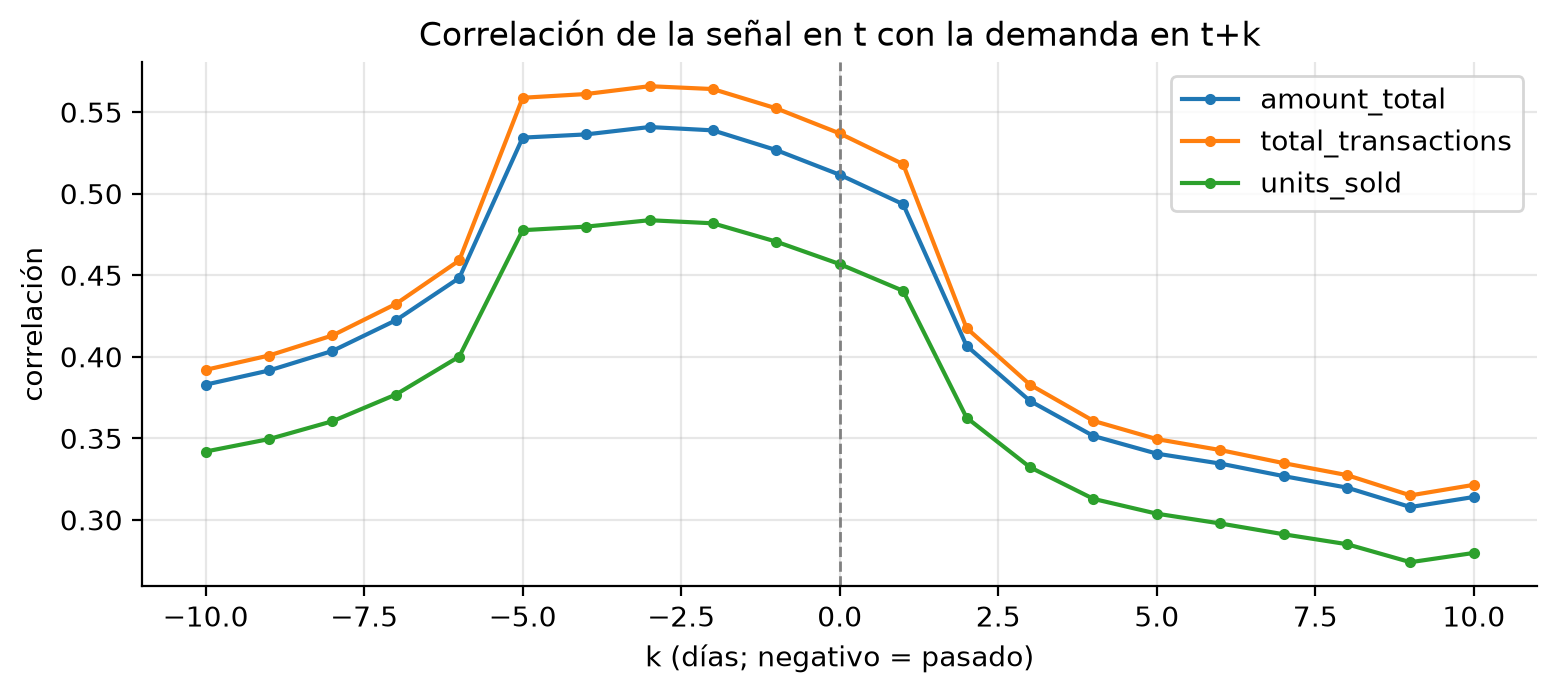

Desfase con mayor correlación: {'amount_total': -3, 'total_transactions': -3, 'units_sold': -3}


,amount_total,total_transactions,units_sold
-4,0.536,0.561,0.480
-3,0.541,0.566,0.484
-2,0.539,0.564,0.482
-1,0.527,0.552,0.471
0,0.512,0.537,0.457
1,0.494,0.518,0.440
2,0.407,0.418,0.363
3,0.373,0.383,0.332


In [2]:
df['l_sig'] = np.log(df.replenishment_signal)
res = {}
for target in ['amount_total', 'total_transactions', 'units_sold']:
    lt = np.log(df[target]); out = {}
    for k in range(-10, 11):
        d = pd.DataFrame({'s': df.l_sig, 'f': lt.groupby(df.serie).shift(-k), 'id': df.serie}).dropna()
        d['s'] -= d.groupby('id').s.transform('mean'); d['f'] -= d.groupby('id').f.transform('mean')
        out[k] = np.corrcoef(d.s, d.f)[0, 1]
    res[target] = pd.Series(out)
CC = pd.DataFrame(res)
ax = CC.plot(marker='o', ms=3, title='Correlación de la señal en t con la demanda en t+k'); ax.axvline(0, color='gray', ls='--', lw=1)
ax.set(xlabel='k (días; negativo = pasado)', ylabel='correlación'); plt.show()
print('Desfase con mayor correlación:', CC.idxmax().to_dict()); CC.loc[[-4, -3, -2, -1, 0, 1, 2, 3]].round(3)

**Lectura.** La señal se parece más a la demanda de **dos o tres días antes** (máximo en k = −3, con 0.54–0.57) que a la del propio día (0.51–0.54), como esperaría un promedio móvil. Pero la correlación sigue alta en k = +1 (0.49–0.52) y **cae de golpe en k = +2** (0.41): esa caída marca dónde termina la ventana. La señal en *t* ya incorpora la demanda de *t + 1*, es decir, **del día siguiente**.

## 2. Reconstrucción exacta
Si la señal es un promedio móvil, debe poder reproducirse. Para tres columnas candidatas se prueban todas las ventanas `[t − pasado, t + futuro]` y se mide en qué % de filas coincide con la señal (tolerancia 0.01, porque está redondeada a 2 decimales).

In [3]:
def wide(col): return df.pivot(index='date', columns='serie', values=col)
def window_mean(W, past, fut):
    acc = None
    for j in range(-fut, past + 1):                 # shift(j) = valor en t − j
        sh = W.shift(j); acc = sh if acc is None else acc + sh
    return acc / (past + fut + 1)                   # NaN si falta cualquier día de la ventana
SIG = wide('replenishment_signal')
cands = {'total_transactions': wide('total_transactions'), 'efectivo+tarjeta': wide('paid'), 'units_sold': wide('units_sold')}
rows = []
for name, W in cands.items():
    for past in range(0, 9):
        for fut in range(0, 5):
            Wm = window_mean(W, past, fut); ok = (SIG.notna() & Wm.notna()).values
            if ok.sum() > 1000:
                rows.append((name, past, fut, past + fut + 1, int(ok.sum()), float(((SIG - Wm).abs().values < 0.01)[ok].mean())))
G = pd.DataFrame(rows, columns=['columna', 'días_pasados', 'días_futuros', 'largo_ventana', 'filas_comparadas', 'coincide']).sort_values('coincide', ascending=False)
G.head(8).assign(coincide=lambda d: (d.coincide * 100).round(2)).rename(columns={'coincide': 'coincide %'}).reset_index(drop=True)

,columna,días_pasados,días_futuros,largo_ventana,filas_comparadas,coincide %
0,total_transactions,5,1,7,200970,99.760
1,efectivo+tarjeta,5,1,7,130614,21.000
2,total_transactions,6,0,7,200970,0.500
3,total_transactions,4,2,7,200970,0.500
4,total_transactions,3,3,7,200970,0.300
5,total_transactions,4,1,6,201468,0.290
6,efectivo+tarjeta,4,2,7,130614,0.290
7,total_transactions,5,0,6,201468,0.280


In [4]:
best = window_mean(cands['total_transactions'], 5, 1); ok = (SIG.notna() & best.notna()).values
print(f'Ventana [t−5, t+1] sobre total_transactions: coincide en {((SIG - best).abs().values < 0.01)[ok].mean():.2%} de {ok.sum():,} filas con señal y ventana completa')
bad = ((SIG - best).abs() >= 0.01) & SIG.notna() & best.notna()
print('Fechas de las filas que no coinciden:', bad.sum(axis=1)[bad.sum(axis=1) > 0].rename(lambda d: d.strftime('%Y-%m-%d')).to_dict())
print('Fechas con señal nula:', sorted(df.loc[df.replenishment_signal.isna() & ~df.is_missing_row, 'date'].dt.strftime('%Y-%m-%d').unique()))
print('\nComprobación manual, STR_001|Abarrotes (la señal de t debe ser el promedio de total_transactions de t−5 … t+1):')
k = 'STR_001|Abarrotes'; man = pd.DataFrame({'total_transactions': cands['total_transactions'][k], 'señal': SIG[k], 'prom. [t−5,t+1]': best[k]}).iloc[:12]
man['coincide'] = (man['señal'] - man['prom. [t−5,t+1]']).abs() < 0.01; man

Ventana [t−5, t+1] sobre total_transactions: coincide en 99.76% de 200,970 filas con señal y ventana completa
Fechas de las filas que no coinciden: {'2023-01-06': 480}
Fechas con señal nula: ['2023-01-01', '2023-01-02']

Comprobación manual, STR_001|Abarrotes (la señal de t debe ser el promedio de total_transactions de t−5 … t+1):


,total_transactions,señal,"prom. [t−5,t+1]",coincide
date,,,,
2023-01-01,833.000,NaN,NaN,False
2023-01-02,"1,298.000",NaN,NaN,False
2023-01-03,"1,614.000","1,546.000",NaN,False
2023-01-04,"1,726.000","1,699.250",NaN,False
2023-01-05,"2,159.000","1,871.000",NaN,False
2023-01-06,"2,558.000","1,947.000","1,787.857",False
2023-01-07,"2,327.000","1,964.290","1,964.286",True
2023-01-08,"2,068.000","1,960.290","1,960.286",True
2023-01-09,"1,270.000","1,948.000","1,948.000",True


**Lectura.**
- **Fórmula exacta:** `replenishment_signal(t)` es el promedio de `total_transactions` de los 7 días `[t−5, t+1]`. Se reproduce en el **99.76 %** de las filas con ventana completa; ninguna otra ventana supera el 0.5 %. Con efectivo + tarjeta solo coincide el 21 %: se construye con `total_transactions`, el campo inflado por la promoción.
- Las 480 filas que no coinciden son una por serie y todas del 6-ene-2023: ese día la ventana incluye al 1-ene y la señal parece calculada sin ese primer valor. No tiene consecuencias.
- Los nulos están en los **dos primeros días** (el cálculo necesita historia), no en los últimos días del periodo como indica el diccionario.

**Conclusión:** la señal no es información independiente. Es un promedio móvil de la propia demanda que **incluye el día a pronosticar y el siguiente**.

## 3. Fuga indirecta: ¿basta un rezago pequeño?
Si `S(t) = (d(t−5) + … + d(t+1)) / 7`, entonces `S(t) − S(t−1) = (d(t+1) − d(t−6)) / 7`: **la señal de ayer ya contiene la demanda de hoy**. Encadenando dos diferencias separadas por 7 días se llega a un horizonte de 14 días:

`d(t) = d(t−14) + 7·[S(t−1) − S(t−2)] + 7·[S(t−8) − S(t−9)]`

Todos los términos de la derecha serían conocidos en el origen *t − 14* si la señal se usara con rezago 1.

In [5]:
TX = cands['total_transactions']
rebuilt = TX.shift(14) + 7 * (SIG.shift(1) - SIG.shift(2)) + 7 * (SIG.shift(8) - SIG.shift(9))
m = rebuilt.notna().values; err = (rebuilt - TX).abs().values[m & TX.notna().values]
print(f'Filas reconstruibles: {len(err):,} | |reconstruida − total_transactions real| < 0.5 en {(err < 0.5).mean():.2%} (mediana del error: {np.median(err):.3f} transacciones)')
ej = pd.DataFrame({'real': TX['STR_002|Abarrotes'], 'reconstruida': rebuilt['STR_002|Abarrotes']}).dropna().iloc[100:106]; ej

Filas reconstruibles: 197,118 | |reconstruida − total_transactions real| < 0.5 en 99.70% (mediana del error: 0.030 transacciones)


,real,reconstruida
date,,
2023-04-25,"1,508.000","1,508.050"
2023-04-26,"1,650.000","1,650.000"
2023-04-27,"2,102.000","2,102.030"
2023-04-28,"1,811.000","1,810.990"
2023-04-29,"2,357.000","2,356.960"
2023-04-30,"4,916.000","4,916.040"


**Lectura.** La demanda del día objetivo se reconstruye con error < 0.5 transacciones en el 99.7 % de las filas (mediana del error: 0.03). Con señales de ayer y antier ya se conoce `total_transactions` de hoy: **un rezago pequeño no evita la fuga** cuando la variable es una función de la demanda. El rezago mínimo válido es *horizonte + largo de la ventana futura* = 14 + 1 = **15 días**.

## 4. Prueba predictiva: ¿cuánto se inflan las métricas?
Horizonte directo de **14 días** (el pronóstico de la fecha *t* solo usa información hasta *t − 14*, más calendario y promoción planeada). LightGBM sobre `log(amount_total)`, tres folds, entrenamiento hasta 14 días antes del inicio de cada fold. Variantes sobre la base de rezagos + calendario + categoría + formato:

| Variante | Válida |
|---|---|
| base (sin señal) | sí |
| + señal en *t* | **no** (usa *t* y *t+1*) |
| + señal con rezago 14 | **no** (su ventana llega hasta *t−13*, más allá del origen) |
| + reconstrucción con rezagos 1-2 y 8-9 (§3) | **no** (reconstruye la demanda objetivo) |
| + señal con rezago 15 | sí (mínimo legítimo: horizonte + 1) |
| + señal con rezago 28 | sí |

In [6]:
H = 14
df['ly'] = np.log(df.amount_total); g = df.groupby('serie')
for L in (14, 21, 28, 35): df[f'lag{L}'] = g.ly.shift(L)
df['same_dow_mean4'] = df[['lag14', 'lag21', 'lag28', 'lag35']].mean(axis=1)
df['roll7'] = g.ly.transform(lambda x: x.shift(H).rolling(7, min_periods=5).mean())
df['roll28'] = g.ly.transform(lambda x: x.shift(H).rolling(28, min_periods=20).mean())
gs = df.groupby('serie').l_sig
df['sig_t'] = df.l_sig
for L in (14, 15, 28): df[f'sig_l{L}'] = gs.shift(L)
df['tx_lag14'] = df.groupby('serie').total_transactions.shift(14)
df['tx_rebuilt'] = df.tx_lag14 + 7 * (df.groupby('serie').replenishment_signal.shift(1) - df.groupby('serie').replenishment_signal.shift(2)) + 7 * (df.groupby('serie').replenishment_signal.shift(8) - df.groupby('serie').replenishment_signal.shift(9))
df['sig_rebuilt'] = np.log(df.tx_rebuilt.clip(lower=1))
for col in ['is_payday', 'is_official_holiday', 'is_weekend', 'is_buen_fin', 'is_navidad_season', 'is_semana_santa']: df[col] = df[col].astype(int)
for col in ['category', 'store_format']: df[col] = df[col].astype('category')
BASE = ['lag14', 'lag21', 'lag28', 'lag35', 'same_dow_mean4', 'roll7', 'roll28', 'day_of_week', 'is_payday', 'is_official_holiday', 'is_weekend',
        'is_buen_fin', 'is_navidad_season', 'is_semana_santa', 'has_promotion', 'category', 'store_format']
VARIANTS = {'base (sin señal)': BASE, '+ señal en t  [NO válida]': BASE + ['sig_t'], '+ señal rezago 14  [NO válida]': BASE + ['sig_l14'],
            '+ reconstrucción rezagos 1-2 y 8-9  [NO válida]': BASE + ['sig_rebuilt'], '+ señal rezago 15  [válida]': BASE + ['sig_l15'], '+ señal rezago 28  [válida]': BASE + ['sig_l28']}
FOLDS = {'sep-2023 (regular)': ('2023-09-01', '2023-09-30'), 'nov-dic 2023 (eventos nuevos)': ('2023-11-01', '2023-12-31'), 'feb-2024 (regular)': ('2024-02-01', '2024-02-29')}
PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100, random_state=0, verbose=-1)
rows = []
for fold, (a, b) in FOLDS.items():
    a, b = pd.Timestamp(a), pd.Timestamp(b); origin = a - pd.Timedelta(days=H)
    tr = df[(df.date <= origin) & ~df.is_missing_row & df.lag14.notna()]; te = df[df.date.between(a, b) & ~df.is_missing_row]
    for name, feats in VARIANTS.items():
        mdl = lgb.LGBMRegressor(**PARAMS).fit(tr[feats], tr.ly); yh = np.exp(mdl.predict(te[feats]))
        rows.append({'fold': fold, 'variante': name, 'WAPE %': wape(te.amount_total, yh) * 100, 'sesgo %': bias(te.amount_total, yh) * 100})
R = pd.DataFrame(rows); W = R.pivot(index='variante', columns='fold', values='WAPE %').loc[list(VARIANTS)]
W['Δ vs base (reg.)'] = W[['sep-2023 (regular)', 'feb-2024 (regular)']].mean(axis=1) - W.loc['base (sin señal)', ['sep-2023 (regular)', 'feb-2024 (regular)']].mean()
print('WAPE % a nivel tienda × categoría × día, horizonte 14 días (piso de ruido ≈ 15.6 %, ver notebook 02):'); W

WAPE % a nivel tienda × categoría × día, horizonte 14 días (piso de ruido ≈ 15.6 %, ver notebook 02):


fold,feb-2024 (regular),nov-dic 2023 (eventos nuevos),sep-2023 (regular),Δ vs base (reg.)
variante,,,,
base (sin señal),17.608,32.278,18.271,0.000
+ señal en t [NO válida],16.978,31.257,18.005,-0.448
+ señal rezago 14 [NO válida],17.567,32.228,18.299,-0.006
+ reconstrucción rezagos 1-2 y 8-9 [NO válida],13.443,24.474,14.075,-4.181
+ señal rezago 15 [válida],17.599,32.246,18.270,-0.005
+ señal rezago 28 [válida],17.596,32.304,18.253,-0.015


**Lectura** (WAPE a nivel serie-día; promedio de los dos folds regulares):
- **Señal en *t*:** mejora el WAPE entre 0.3 y 1.0 puntos (fuga real pero pequeña, porque la señal suaviza 7 días y el día *t* pesa 1/7).
- **Reconstrucción con rezagos 1–2 y 8–9:** el WAPE baja ≈ **4.2 puntos** en los folds regulares (a 14.1 % y 13.4 %) y **7.8 puntos** en nov–dic (de 32.3 % a 24.5 %). Esos valores están **por debajo del piso de ruido (≈ 15.6 %, notebook 02)**: ningún modelo legítimo puede lograrlos. Es el síntoma de fuga, y se detecta sin conocer su causa.
- **Rezago 14:** ganancia 0.0. Su ventana llega hasta *t−13* (un día más allá del origen), pero ese día está lejos del objetivo y no ayuda; sigue siendo inválido.
- **Rezagos 15 y 28 (válidos):** ganancia de **0.0 puntos** en los tres folds. Usada correctamente, la señal no aporta nada que no den los rezagos y medias móviles de la propia serie.

**Lección de método:** un rezago «razonable» no garantiza ausencia de fuga, y un WAPE por debajo del piso de ruido debe tratarse como alarma y no como éxito.

## 5. La señal hereda el defecto de `total_transactions`
Como se construye con `total_transactions` (inflado en días con promoción, ver notebook 02), la señal debería quedar inflada en proporción a los días con promoción dentro de su ventana.

In [7]:
PROMO = wide('has_promotion'); PAID_W = window_mean(cands['efectivo+tarjeta'], 5, 1); FR = window_mean(PROMO, 5, 1)
z = pd.DataFrame({'sig': SIG.stack(), 'paid_w': PAID_W.stack(), 'frac': FR.stack()}).dropna()
z['exceso'] = z.sig / z.paid_w - 1; z['días con promo en la ventana'] = (z.frac * 7).round().astype(int).clip(upper=3).map({0: '0', 1: '1', 2: '2', 3: '3 o más'})
print(z.groupby('días con promo en la ventana').exceso.agg(['mean', 'count']).rename(columns={'mean': 'exceso medio de la señal vs. efectivo+tarjeta', 'count': 'filas'}).to_string(formatters={'exceso medio de la señal vs. efectivo+tarjeta': '{:+.1%}'.format}))
print(f'\nCorrelación entre fracción de días con promoción en la ventana y exceso de la señal: {np.corrcoef(z.frac, z.exceso)[0, 1]:.3f}')

                             exceso medio de la señal vs. efectivo+tarjeta  filas
días con promo en la ventana                                                     
0                                                                    +0.0%  27505
1                                                                    +3.2%  48197
2                                                                    +6.4%  35492
3 o más                                                             +10.4%  19420

Correlación entre fracción de días con promoción en la ventana y exceso de la señal: 0.889


**Lectura.** El exceso de la señal sobre efectivo + tarjeta crece ≈ 3 % por cada día con promoción dentro de la ventana (+3.2 %, +6.4 %, +10.4 % con 3 o más) y la correlación es 0.89. Además de filtrar demanda, la señal **hereda el artefacto de `total_transactions` y se contamina con la promoción**.

## Conclusiones
| Pregunta | Respuesta |
|---|---|
| ¿Qué es la señal? | Promedio móvil de 7 días de `total_transactions` en `[t−5, t+1]` (99.76 % de coincidencia exacta) |
| ¿Hay fuga? | **Sí.** Incluye la demanda del día pronosticado y la del siguiente; con señales vecinas rezagadas se reconstruye `total_transactions` del día objetivo |
| ¿Cuánto infla las métricas? | 0.3–1.0 puntos de WAPE usada en *t*; ≈ 4–8 puntos reconstruyéndola con rezagos pequeños (WAPE por debajo del piso de ruido) |
| ¿Sirve con un rezago legítimo (≥ 15 días)? | Es válida pero **no aporta nada** (0.0 puntos) |
| ¿Tiene otro defecto? | Hereda la inflación de `total_transactions` en días con promoción (+3 % por día de promoción en la ventana) |

**Decisión:** `replenishment_signal` se **excluye por completo** de los features (con ningún rezago) y sus nulos no se imputan. Los rezagos y medias móviles se calculan sobre `amount_total`. Esta decisión es robusta a un cambio de horizonte.

**Reglas que quedan para el pipeline de features:**
1. Toda variable derivada de la demanda debe verificarse contra su ventana: rezago mínimo = horizonte + largo del futuro que incluya.
2. Los tests de features comprobarán que ningún feature usa fechas posteriores al origen.
3. Un WAPE serie-día por debajo de ≈ 15 % se trata como alarma de fuga.